## Analyzing a Dataset Using SQL and Python

Required libraries

In [1]:
!pip install pandas
!pip install ipython-sql prettytable 

import prettytable

prettytable.DEFAULT = 'DEFAULT'

import csv, sqlite3
import pandas
import matplotlib.pyplot as plt
import numpy as np

con = sqlite3.connect("DB.db")
cur = con.cursor()

!pip install ipython-sql
%load_ext sql

### Understand the datasets

This project uses two datasets from the City of Paris Open Data Portal to explore bicycle traffic and the availability of Vélib' stations in Paris.

#### 1. Bicycle Traffic Counts in Paris

This dataset contains bicycle traffic counts collected by monitoring stations across Paris. It can be used to explore variations in bicycle traffic across locations and over time, including differences by hour and day of the week.

The dataset is available on the Paris Open Data Portal:

[Paris Bicycle Traffic Counts](https://opendata.paris.fr/explore/dataset/comptage-velo-donnees-compteurs/)

#### 2. Vélib' Station Locations

This dataset contains information about Vélib' bicycle-sharing stations in Paris, including their locations and station characteristics. It can be used to explore the distribution of bicycle-sharing infrastructure across the city and compare station locations with bicycle traffic monitoring points.

The dataset is available on the Paris Open Data Portal:

[Vélib' Station Locations](https://opendata.paris.fr/explore/dataset/velib-emplacement-des-stations/)

Load the data on to the database `DB.db`.

In [2]:
# Bike data
url_bike = "https://opendata.paris.fr/api/explore/v2.1/catalog/datasets/comptage-velo-donnees-compteurs/exports/csv?lang=fr&timezone=Europe%2FParis"

bike_df = pandas.read_csv(url_bike, sep=";")

bike_df.to_sql("BIKE_DATA", con, if_exists="replace", index=False)

# Velib data
url_velib = "https://opendata.paris.fr/api/explore/v2.1/catalog/datasets/velib-emplacement-des-stations/exports/csv?lang=fr&timezone=Europe%2FParis"

velib_df = pandas.read_csv(url_velib, sep=";")

velib_df.to_sql("VELIB_STATIONS", con, if_exists="replace", index=False)

%sql sqlite:///DB.db

#### Some informations

1. Points with the highest and the lowest bicycle traffic

In [3]:
%%sql 
SELECT name AS address, ROUND(AVG(sum_counts)) AS average_bicycle_count
FROM BIKE_DATA
GROUP BY address
ORDER BY average_bicycle_count DESC LIMIT 5

 * sqlite:///DB.db
Done.


address,average_bicycle_count
Totem 73 boulevard de Sébastopol,337.0
102 boulevard de Magenta,251.0
89 boulevard de Magenta,242.0
Totem 64 Rue de Rivoli,232.0
35 boulevard de Ménilmontant,218.0


In [4]:
%%sql 
SELECT name AS address, ROUND(AVG(sum_counts)) AS average_bicycle_count
FROM BIKE_DATA
GROUP BY address
ORDER BY average_bicycle_count LIMIT 5

 * sqlite:///DB.db
Done.


address,average_bicycle_count
106 avenue Denfert Rochereau,0.0
Face au 8 avenue de la porte de Charenton,3.0
27 boulevard Davout,20.0
28 boulevard Diderot,22.0
16 avenue de la Porte des Ternes,26.0


2. Times when bicycles are used most

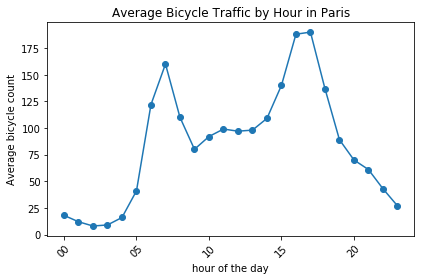

In [5]:
query = """
SELECT
    strftime('%H', date) AS hour,
    CAST(ROUND(AVG(sum_counts)) AS INTEGER) AS average_bicycle_count
FROM BIKE_DATA
WHERE sum_counts IS NOT NULL
GROUP BY hour
ORDER BY hour;
"""
result = pandas.read_sql_query(query, con)

result.plot(
    x="hour",
    y="average_bicycle_count",
    kind="line",
    marker="o",
    legend=False
)

plt.xlabel("hour of the day")
plt.ylabel("Average bicycle count")
plt.title("Average Bicycle Traffic by Hour in Paris")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

3. Days of the week with the highest bicycle traffic in Paris

In [6]:
%%sql
SELECT
    CASE strftime('%w', date)
        WHEN '0' THEN 'Sunday'
        WHEN '1' THEN 'Monday'
        WHEN '2' THEN 'Tuesday'
        WHEN '3' THEN 'Wednesday'
        WHEN '4' THEN 'Thursday'
        WHEN '5' THEN 'Friday'
        WHEN '6' THEN 'Saturday'
    END AS day_of_week,
    CAST(ROUND(AVG(sum_counts)) AS INTEGER) AS average_bicycle_count
FROM BIKE_DATA
WHERE sum_counts IS NOT NULL
  AND date IS NOT NULL
GROUP BY strftime('%w', date)
ORDER BY strftime('%w', date)

 * sqlite:///DB.db
Done.


day_of_week,average_bicycle_count
Sunday,57
Monday,89
Tuesday,97
Wednesday,92
Thursday,97
Friday,86
Saturday,69


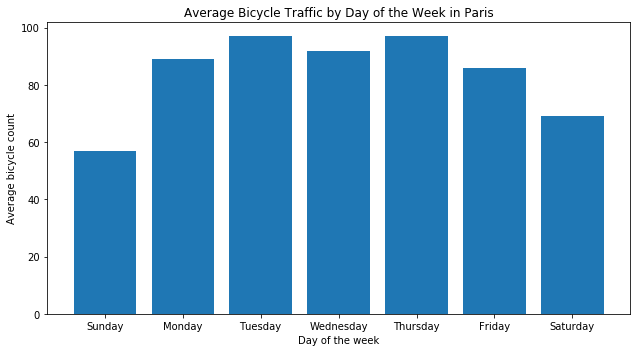

In [7]:
query = """
SELECT
    CASE strftime('%w', date)
        WHEN '0' THEN 'Sunday'
        WHEN '1' THEN 'Monday'
        WHEN '2' THEN 'Tuesday'
        WHEN '3' THEN 'Wednesday'
        WHEN '4' THEN 'Thursday'
        WHEN '5' THEN 'Friday'
        WHEN '6' THEN 'Saturday'
    END AS day_of_week,
    CAST(ROUND(AVG(sum_counts)) AS INTEGER) AS average_bicycle_count
FROM BIKE_DATA
WHERE sum_counts IS NOT NULL
  AND date IS NOT NULL
GROUP BY strftime('%w', date)
ORDER BY strftime('%w', date);
"""

result = pandas.read_sql_query(query, con)

plt.figure(figsize=(9, 5))

plt.bar(result["day_of_week"], result["average_bicycle_count"])

plt.xlabel("Day of the week")
plt.ylabel("Average bicycle count")
plt.title("Average Bicycle Traffic by Day of the Week in Paris")

plt.tight_layout()
plt.show()

4. Total number of Velib stations in Paris

In [8]:
%sql SELECT COUNT(*) AS total_number_of_stations_in_Paris FROM VELIB_STATIONS; 

 * sqlite:///DB.db
Done.


total_number_of_stations_in_Paris
1519


5. Stations with the Highest and Lowest Capacity

In [9]:
%sql SELECT name AS station, capacity FROM VELIB_STATIONS ORDER BY capacity DESC LIMIT 5 

 * sqlite:///DB.db
Done.


station,capacity
Invalides - Quai d'Orsay,410
Concorde - Place de la Madeleine,409
Station Tour de France,200
Hippodrome de Paris Vincennes,100
Jean Macé - Faidherbe,78


In [10]:
%sql SELECT name AS station, capacity FROM VELIB_STATIONS WHERE capacity>0 ORDER BY capacity LIMIT 5 

 * sqlite:///DB.db
Done.


station,capacity
Chabrol - d'Hauteville,11
Brancion - Lefebvre,11
Hôpital - Campo-Formio,11
Messine - Place Du Pérou,12
Desaix - Edgar Faure,12


6. Do areas with the most bicycle traffic have more Vélib' stations?

In [11]:
# Split coordinates into latitude and longitude
bike_df[["latitude", "longitude"]] = (
    bike_df["coordinates"]
    .str.split(",", expand=True)
    .astype(float)
)

velib_df[["latitude", "longitude"]] = (
    velib_df["coordonnees_geo"]
    .str.split(",", expand=True)
    .astype(float)
)

bike_summary = (
    bike_df.groupby(
        ["id_compteur", "nom_compteur", "latitude", "longitude"],
        as_index=False
    )["sum_counts"]
    .mean()
    .rename(columns={"sum_counts": "average_bicycle_count"})
)

# Calculate distances using the Haversine formula
bike_rad = np.radians(bike_summary[["latitude", "longitude"]].values)
velib_rad = np.radians(velib_df[["latitude", "longitude"]].values)

lat1 = velib_rad[:, 0][:, None]
lon1 = velib_rad[:, 1][:, None]
lat2 = bike_rad[:, 0][None, :]
lon2 = bike_rad[:, 1][None, :]

dlat = lat2 - lat1
dlon = lon2 - lon1

a = (
    np.sin(dlat / 2) ** 2
    + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
)

distances = 6371000 * 2 * np.arcsin(np.sqrt(a))

# Find the closest counter to each Vélib' station
nearest_idx = distances.argmin(axis=1)
nearest_distance = distances.min(axis=1)

station_analysis = velib_df[
    ["stationcode", "name", "capacity", "latitude", "longitude"]
].copy()

station_analysis["nearest_counter"] = (
    bike_summary.iloc[nearest_idx]["nom_compteur"].values
)

station_analysis["distance_m"] = nearest_distance

station_analysis["average_bicycle_count"] = (
    bike_summary.iloc[nearest_idx]["average_bicycle_count"].values
)

# Keep stations with a counter within 500 metres
station_analysis = station_analysis[
    station_analysis["distance_m"] <= 500
].copy()

station_analysis.to_sql(
    "STATION_TRAFFIC",
    con,
    if_exists="replace",
    index=False
)

In [12]:
%%sql
SELECT
    CASE
        WHEN average_bicycle_count < 50 THEN 'Low traffic'
        WHEN average_bicycle_count < 150 THEN 'Medium traffic'
        ELSE 'High traffic'
    END AS traffic_level,
    COUNT(*) AS number_of_stations,
    ROUND(AVG(average_bicycle_count), 2) AS average_bicycle_count
FROM STATION_TRAFFIC
GROUP BY traffic_level
ORDER BY average_bicycle_count;

 * sqlite:///DB.db
Done.


traffic_level,number_of_stations,average_bicycle_count
Low traffic,71,34.42
Medium traffic,227,82.6
High traffic,61,222.82


In [13]:
con.close()